# NN_L13_hourly_profile

**Mean Romanian day-ahead price by delivery hour in 2019, 2022, 2024 and 2026 (January-October): the solar trough at midday. Source: energy-charts.info (Fraunhofer ISE), Romanian day-ahead prices.**

Neural Networks and Deep Learning (NN), Lecture 13 · Daniel Traian Pele, Bucharest University of Economic Studies

[Open in Colab](https://colab.research.google.com/github/danpele/NEURAL_BIZ/blob/main/Quantlets/L13/NN_L13_hourly_profile/NN_L13_hourly_profile.ipynb)

In [1]:
import os
# course data: the local copy of the repository if there is one, else the public repository on GitHub
_LOCAL = os.path.join('..', '..', '..', 'data', 'clean')
DATA = _LOCAL + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/data/clean/'
REPO = os.path.join('..', '..', '..') + os.sep if os.path.isdir(_LOCAL) else 'https://raw.githubusercontent.com/danpele/NEURAL_BIZ/main/'

In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
# course chart style: transparent background, no gridlines, legend at the bottom outside the axes, four-digit years
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.edgecolor': '#222222', 'axes.labelcolor': '#222222', 'xtick.color': '#222222', 'ytick.color': '#222222',
    'text.color': '#222222', 'font.size': 11, 'axes.labelsize': 11, 'legend.fontsize': 10.5, 'legend.frameon': False,
    'lines.linewidth': 1.4, 'font.family': 'DejaVu Sans'})
SERIES = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
PAL = {'data': '#2a78d6', 'model': '#eb6834', 'benchmark': '#1baf7a', 'alt': '#eda100',
       'train': '#2a78d6', 'valid': '#eb6834', 'test': '#6250d6', 'positive': '#e34948', 'negative': '#2a78d6'}


def legend_bottom(fig, ncol=4):
    h, l_ = [], []
    for ax in fig.axes:
        for hh, ll in zip(*ax.get_legend_handles_labels()):
            if ll not in l_:
                h.append(hh); l_.append(ll)
    if h:
        fig.legend(h, l_, loc='lower center', ncol=min(ncol, len(h)), bbox_to_anchor=(0.5, 0.0), frameon=False)


def show(key, label, value):
    # print a number of the slide; [key] = its name in lectures/Lk/Lk_numbers.json
    print(f'{label} = {value}   [{key}]')

lowest hourly mean 2026 (EUR/MWh) = 67.9   [facts.profile.2026.min]
highest hourly mean 2026 (EUR/MWh) = 217.05   [facts.profile.2026.max]
cheapest hour 2026 = 13   [facts.profile.2026.min_hour]


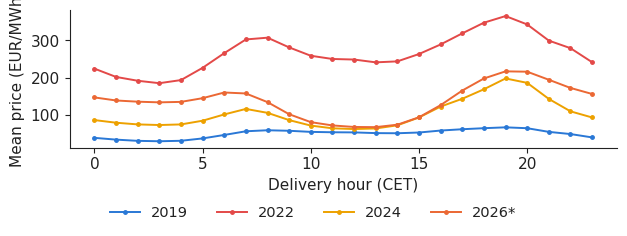

In [3]:
x = pd.read_csv(DATA + 'power_da_prices_hourly_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')
x.index = x.index.tz_convert('Europe/Brussels')
def day_matrix(s):
    df = pd.DataFrame({'v': s.values, 'd': s.index.tz_localize(None).normalize(), 'h': s.index.hour}, index=s.index)
    return df.groupby(['d', 'h'])['v'].mean().unstack('h').reindex(columns=range(24))
RO = day_matrix(x['RO']).loc[:'2026-10-31']
DE = day_matrix(x['DE_LU']).loc[:'2026-10-31']
prof = {y: RO.loc[str(y)].mean(axis=0) for y in [2019, 2022, 2024, 2026]}
show('facts.profile.2026.min', 'lowest hourly mean 2026 (EUR/MWh)', round(float(prof[2026].min()), 2))
show('facts.profile.2026.max', 'highest hourly mean 2026 (EUR/MWh)', round(float(prof[2026].max()), 2))
show('facts.profile.2026.min_hour', 'cheapest hour 2026', int(prof[2026].idxmin()))
fig, ax = plt.subplots(figsize=(6.4, 2.4))
for y, c in zip(prof, [SERIES[0], SERIES[7], SERIES[3], SERIES[1]]):
    ax.plot(range(24), prof[y].values, marker='o', ms=2.5, color=c, label=str(y) + ('*' if y == 2026 else ''))
ax.set_xlabel('Delivery hour (CET)')
ax.set_ylabel('Mean price (EUR/MWh)')
legend_bottom(fig)
fig.tight_layout(rect=(0, 0.1, 1, 1))
fig.savefig('hourly_profile.png', dpi=200, transparent=True, bbox_inches='tight')
plt.show()